# 6.0 - Model: Decision Tree (baseline variant)

**Training and evaluation of the Decision Tree classifier on the baseline variant of the TF-IDF data.**

## Theoretical basis

Decision Tree is a model that makes predictions through a sequence of consecutive yes/no questions about individual features (e.g. "is the TF-IDF weight for 'bad' greater than 0.05?"), branching based on the answers until it reaches a leaf that predicts the class.

The tree consists of an initial (root) node, internal nodes that represent decisions, branches that represent the results of decisions, and leaves (leaf) where the final prediction is made. This division of the data is called a split, and the process is repeated on the newly created subsets until the conditions for stopping the branching are met.

When building the tree, the algorithm searches at each node for the feature and threshold that best separate the classes, using Gini impurity as the measure of impurity.

The goal is to obtain, after the split, subsets that are as homogeneous as possible in terms of positive and negative reviews.:

  - A node is completely "pure" (`Gini = 0`) if it contains examples from only one class
  - A node is most "impure" (`Gini = 0.5` for binary classification) if the classes are completely mixed 50/50

<br>

Advantage: the result is directly interpretable - it is possible to follow the exact sequence of decisions that led to each individual prediction.

Disadvantages (Prone to overfitting):
- Without restrictions, the tree can continue branching until each leaf contains only 1-2 examples, which means it has literally "memorized" the train set instead of learning patterns that generalize to new data
- This is especially pronounced in our case: with 64.803 features, the tree has a huge number of possible splitting rules available at each step, so the risk is greater than with typical, lower-dimensional data
- Therefore, we control the complexity of the tree using the `max_depth` and `min_samples_leaf` hyperparameters, whose values we deliberately search using `GridSearchCV`


## Processing flow:

1. We load the previously prepared baseline TF-IDF data using the `load_variant()` function

2. We create a `DecisionTreeClassifier` and define the `max_depth` and `min_samples_leaf` hyperparameter values that `GridSearchCV` will test

3. We call the shared `train_and_evaluate()` function:
    1. GridSearchCV on the TRAIN set:
        - tests all combinations of hyperparameters from the param_grid
        - uses k-fold cross-validation (5 folds by default)
        - selects the hyperparameter combination that gives the best F1 score
    2. Final model:
        - after selecting the best hyperparameters, GridSearchCV trains the best model on the entire TRAIN set
    3. Evaluation:
        - the best model is used on the TEST set for the first time
        - accuracy, precision, recall, and F1 are calculated, and a confusion matrix is created
    4. Saving the results

4. We analyze `feature_importances_` to see which terms contribute the most to the tree's decisions


In [1]:
import sys
sys.path.append("..")

import numpy as np
import joblib

from src.data_io import load_variant
from src.modeling import train_and_evaluate

from sklearn.tree import DecisionTreeClassifier

## Loading the data

We load the stemmed variant (TF-IDF matrices + labels), saved in `3_vectorization.ipynb`.


In [2]:
X_train, X_test, y_train, y_test = load_variant("baseline")

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Train: (39665, 64803)
Test:  (9917, 64803)


## Model and hyperparameters

Hyperparameters: `max_depth` and `min_samples_leaf`

- `max_depth` - maximum depth of the tree (how many consecutive queries can be made at most before a prediction must be made)
  - Smaller depth → simpler, more generalized tree
  - Greater depth → more complex tree, greater risk of overfitting

- `min_samples_leaf` - minimum number of examples that a leaf must contain for a split to be allowed
  - A larger value prevents the tree from making splits based on only a few (possibly random) examples

`criterion` - we leave it at the default Gini index - we deliberately search only the two hyperparameters that have the greatest impact on overfitting, rather than all possible combinations.


In [3]:
model = DecisionTreeClassifier(random_state=1)

param_grid = {
    "max_depth": [5, 8, 10, 12, 15, 20, 30],
    "min_samples_leaf": [1, 2, 3, 5],
}

## Training and evaluation

Calls `train_and_evaluate()` from `src/modeling.py`.

The function tests all specified combinations of `max_depth` and `min_samples_leaf` values using 5-fold GridSearchCV on the train set, selects the combination with the best F1 score, then trains the best model on the entire train set and evaluates it on the test set.

The results are saved as the model, metrics, and confusion matrix.


========== decision_tree (base) ==========
Best parameters: {'max_depth': 10, 'min_samples_leaf': 2}
GridSearchCV time: 1136.1s

Accuracy  : 0.7333
Precision : 0.6910
Recall    : 0.8475
F1        : 0.7613


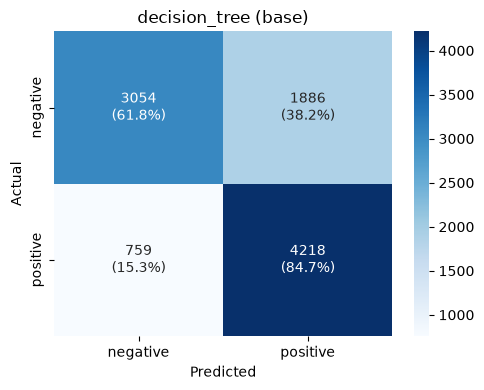


Saved:
  ..\models\decision_tree_base.joblib
  ..\results\metrics\decision_tree_base.json
  ..\results\figures\decision_tree_base_confusion_matrix.png


In [4]:
metrics = train_and_evaluate(
    model=model,
    param_grid=param_grid,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="decision_tree",
    variant="base",
)

## Most influential terms (feature importance)

`feature_importances_` represents a measure of the importance of each feature in building the tree.

The value shows how much a particular term contributed to reducing "impurity" through splits in the tree, where the values are always non-negative.

A higher value means that the term had a greater influence on the decisions made by the tree.

Feature importance does not show the direction of influence, meaning it does not indicate whether a term contributes to positive or negative sentiment. Therefore, here we obtain a single ranking of the most important terms.

We load the saved model and vectorizer back from disk in order to associate the `feature_importances_` values with specific terms.


In [5]:
best_model = joblib.load("../models/decision_tree_base.joblib")
vectorizer = joblib.load("../models/tfidf_vectorizer_base.joblib")

feature_names = np.array(vectorizer.get_feature_names_out())
importances = best_model.feature_importances_

top_idx = np.argsort(importances)[-20:][::-1]

print("Top 20 most influential terms:")
for idx in top_idx:
    print(f"  {feature_names[idx]:30s}  {importances[idx]:.4f}")

n_zero_importance = np.sum(importances == 0)
print(f"\nNumber of terms that the tree never used for splitting: {n_zero_importance} out of {len(importances)} ({n_zero_importance / len(importances):.1%})")

Top 20 most influential terms:
  bad                             0.2424
  worst                           0.1509
  great                           0.1001
  waste                           0.0826
  awful                           0.0639
  boring                          0.0408
  nothing                         0.0393
  excellent                       0.0362
  poor                            0.0283
  stupid                          0.0231
  terrible                        0.0118
  best                            0.0078
  wasted                          0.0069
  wonderful                       0.0062
  not even                        0.0053
  perfect                         0.0039
  not                             0.0039
  favorite                        0.0039
  one best                        0.0037
  make                            0.0037

Number of terms that the tree never used for splitting: 64617 out of 64803 (99.7%)


## Conclusions

- Best `max_depth`: 10 and `min_samples_leaf`: 2

- Results:
  - Accuracy  : 0.7333
  - Precision : 0.6910
  - Recall    : 0.8475
  - F1        : 0.7613

- The obtained results show that bad is the most influential term in building the tree, with a higher `feature_importance_` than the other terms.
Among the most important terms are also other words that can intuitively be associated with sentiment, such as worst, awfull, great, bad, poor and best.

- Interestingly, terms such as favourite, one best and perfect also appear among the most influential terms, but with relatively small `feature_importance_` values, even though these are intuitively very positive words.

- Out of a total of 64.803 features, the tree used only 186 for splitting, while 64.617 terms have a `feature_importance_` equal to zero.
This shows that during construction, the tree used a very small portion of the available TF-IDF space to make its decisions.

- This provides the basis for comparison with Random Forest in the next notebook (`7.0`) - the same type of model, but as an ensemble rather than a single tree.
